,Missing hours,Missing (%)
PresentWeather(rank),32441,57.69
MaximumWindSpeed(m/s),741,1.32
MinimumWindSpeed(m/s),741,1.32
WindSpeed(m/s),618,1.10
WindDirection(deg),501,0.89
MaximumPrecipitationIntensity(mm/h),321,0.57
PrecipitationAmount(mm),303,0.54
RelativeHumidity(%),289,0.51
AirPressure(hPa),210,0.37
AirTemperature(degC),208,0.37


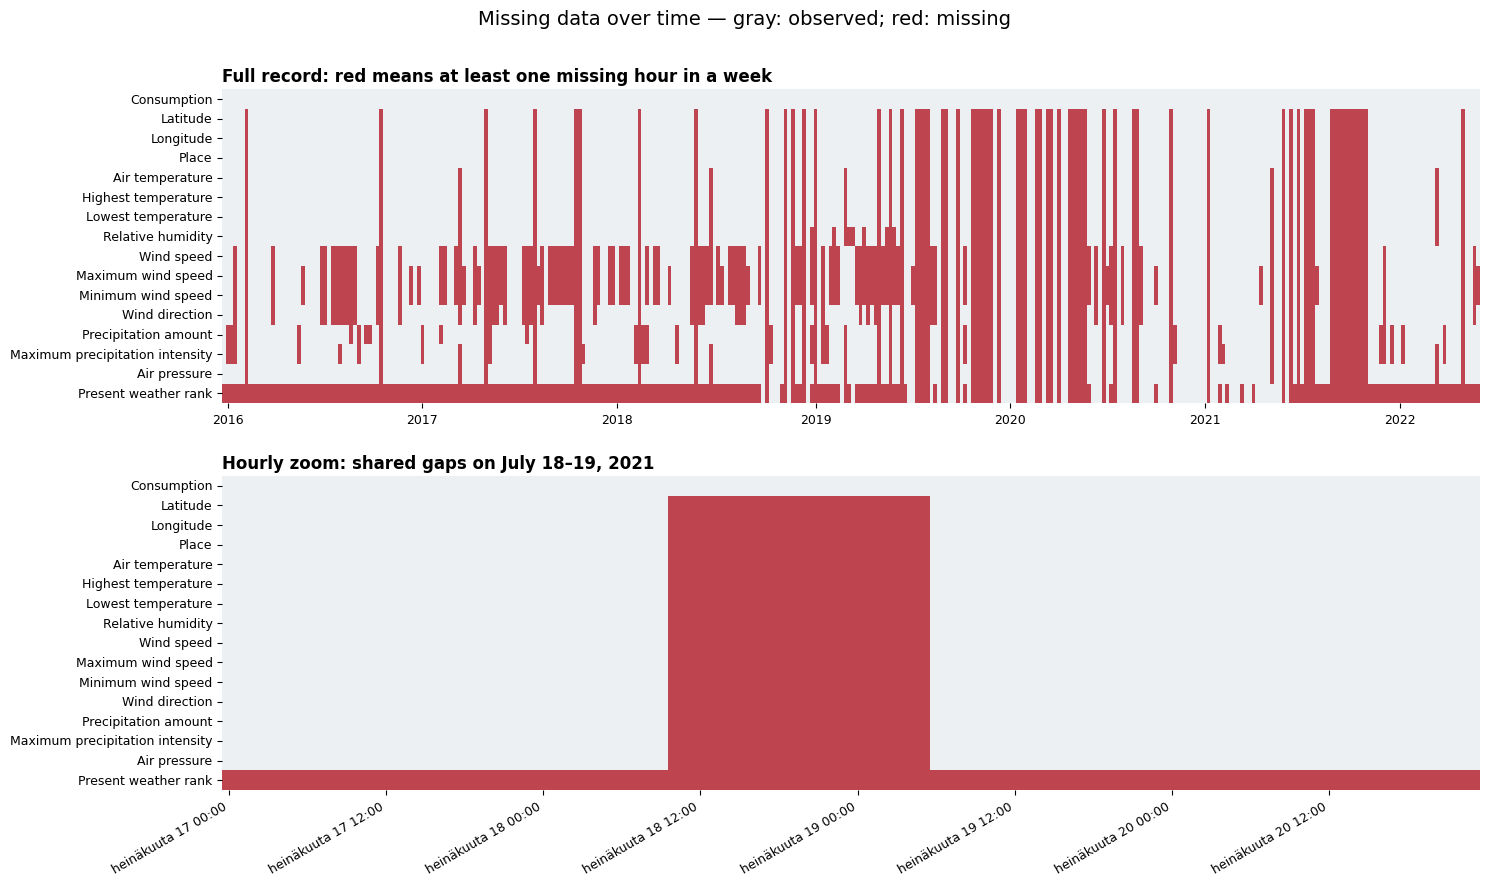

,Start,End,Missing hours,Missing together (excluding weather rank),Consumption available throughout?
0,2017-05-14 06:00:00,2017-05-16 15:00:00,58,All 4 wind columns,Yes
1,2017-05-11 15:00:00,2017-05-13 00:00:00,34,All 4 wind columns,Yes
2,2021-07-18 10:00:00,2021-07-19 05:00:00,20,All 3 location columns; All 11 weather measure...,Yes
3,2016-01-18 07:00:00,2016-01-18 18:00:00,12,Both precipitation columns,Yes
4,2016-01-19 19:00:00,2016-01-20 06:00:00,12,Both precipitation columns,Yes
5,2016-01-20 19:00:00,2016-01-21 06:00:00,12,Both precipitation columns,Yes
6,2016-05-20 07:00:00,2016-05-20 18:00:00,12,Both precipitation columns,Yes
7,2017-05-21 12:00:00,2017-05-21 23:00:00,12,All 4 wind columns,Yes
8,2017-05-13 10:00:00,2017-05-13 19:00:00,10,All 4 wind columns,Yes
9,2017-05-19 14:00:00,2017-05-19 23:00:00,10,All 4 wind columns,Yes


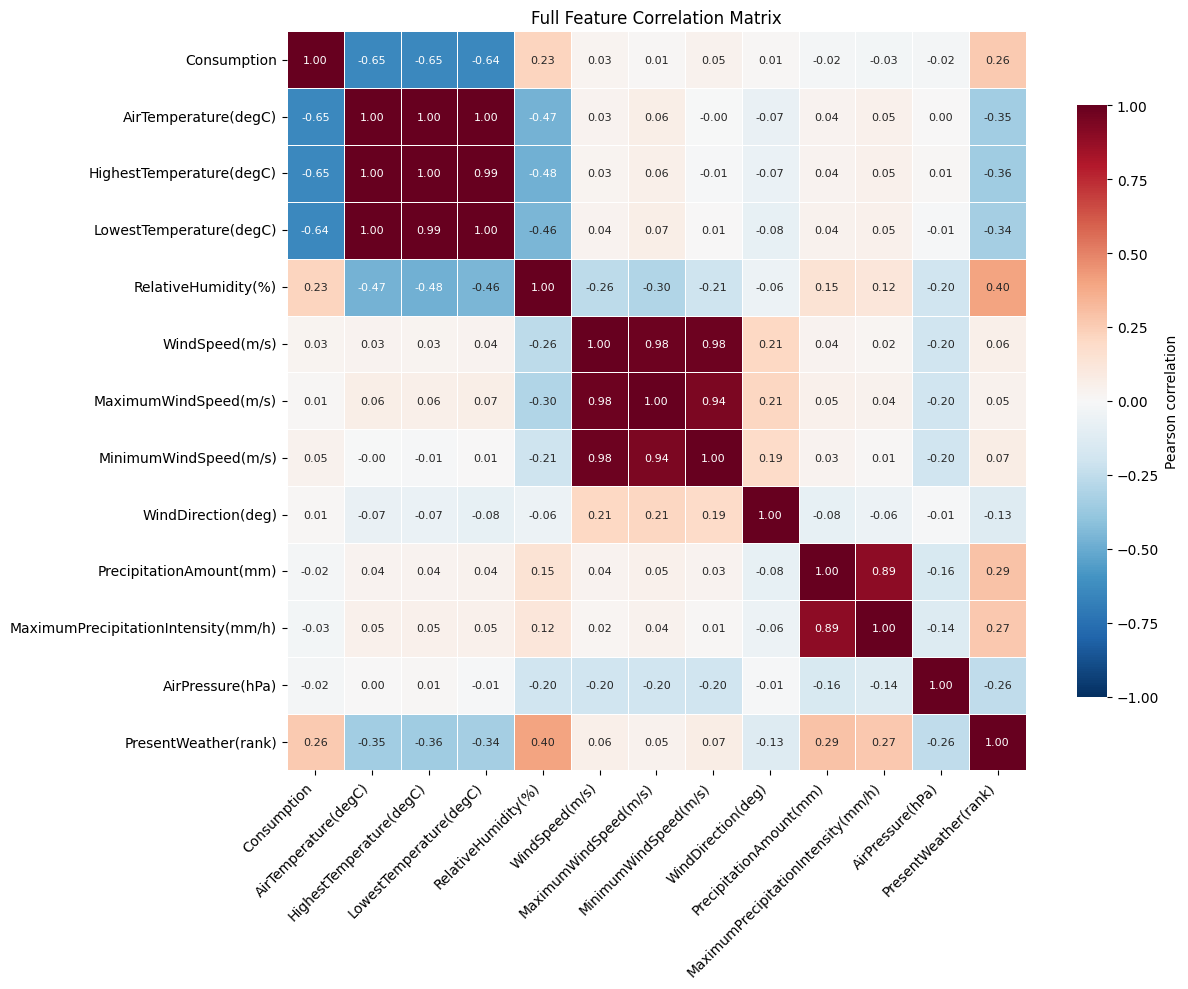

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Load the dataset
df = pd.read_csv('dataset_mansion.csv', index_col=0)

df['Consumption'] = pd.to_numeric(
    df['Consumption'].astype('string').str.replace(',', '.', regex=False),
    errors='raise'
)
df['MTime'] = pd.to_datetime(df['MTime'], errors='raise')
assert df['MTime'].notna().all(), 'Check missing timestamps first.'
assert not df['MTime'].duplicated().any(), 'Check duplicate timestamps first.'
df = df.set_index('MTime').sort_index()

expected = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(expected), 'This analysis expects a complete hourly timeline.'

missing = df.isna()

summary = pd.DataFrame({
    'Missing hours': missing.sum(),
    'Missing (%)': missing.mean().mul(100).round(2)
}).sort_values('Missing hours', ascending=False)
display(summary)




# Weekly overview: keep a week visible even if only one hour is missing.
weekly_missing = missing.resample('W-MON', label='left', closed='left').max()

# Hourly zoom: change these dates to inspect a different period.
zoom = missing.loc['2021-07-17':'2021-07-20']

labels = {
    'Consumption': 'Consumption', 'Latitude': 'Latitude',
    'Longitude': 'Longitude', 'Place': 'Place',
    'AirTemperature(degC)': 'Air temperature',
    'HighestTemperature(degC)': 'Highest temperature',
    'LowestTemperature(degC)': 'Lowest temperature',
    'RelativeHumidity(%)': 'Relative humidity',
    'WindSpeed(m/s)': 'Wind speed',
    'MaximumWindSpeed(m/s)': 'Maximum wind speed',
    'MinimumWindSpeed(m/s)': 'Minimum wind speed',
    'WindDirection(deg)': 'Wind direction',
    'PrecipitationAmount(mm)': 'Precipitation amount',
    'MaximumPrecipitationIntensity(mm/h)': 'Maximum precipitation intensity',
    'AirPressure(hPa)': 'Air pressure',
    'PresentWeather(rank)': 'Present weather rank'
}

fig, axes = plt.subplots(2, 1, figsize=(15, 9))
colors = ListedColormap(['#edf0f3', '#be4450'])
for ax, data, title in [
    (axes[0], weekly_missing, 'Full record: red means at least one missing hour in a week'),
    (axes[1], zoom, 'Hourly zoom: shared gaps on July 18–19, 2021')
]:
    sns.heatmap(data.rename(columns=labels).T.astype(int), ax=ax,
                cmap=colors, vmin=0, vmax=1, cbar=False,
                xticklabels=False, yticklabels=True)
    ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0, labelsize=9)

# Label the overview by year and the zoom every 12 hours.
year_ticks = np.flatnonzero(
    np.r_[False, weekly_missing.index.year[1:] != weekly_missing.index.year[:-1]]
)
year_labels = weekly_missing.index[year_ticks].strftime('%Y').tolist()
axes[0].set_xticks(year_ticks + .5)
axes[0].set_xticklabels(year_labels, rotation=0, fontsize=9)
ticks = np.arange(0, len(zoom), 12)
axes[1].set_xticks(ticks + .5)
axes[1].set_xticklabels(zoom.index[ticks].strftime('%b %d %H:%M'),
                        rotation=30, ha='right', fontsize=9)
fig.suptitle('Missing data over time — gray: observed; red: missing', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .97], h_pad=2)
plt.show()



# Leave weather rank aside when identifying shared gaps.
checked_cols = [c for c in df.columns if c != 'PresentWeather(rank)']
mask = missing[checked_cols]

# A new event begins whenever any column changes missing/observed status.
new_event = mask.ne(mask.shift()).any(axis=1)
event_id = new_event.cumsum()

location_cols = ['Latitude', 'Longitude', 'Place']
weather_cols = [c for c in checked_cols
                if c not in ['Consumption'] + location_cols]

def describe_columns(columns):
    # Shorten the label only when the entire group is missing.
    remaining = list(columns)
    labels = []
    wind_cols = ['WindSpeed(m/s)', 'MaximumWindSpeed(m/s)',
                 'MinimumWindSpeed(m/s)', 'WindDirection(deg)']
    rain_cols = ['PrecipitationAmount(mm)', 'MaximumPrecipitationIntensity(mm/h)']
    for group, label in [(location_cols, 'All 3 location columns'),
                         (weather_cols, 'All 11 weather measurements'),
                         (wind_cols, 'All 4 wind columns'),
                         (rain_cols, 'Both precipitation columns')]:
        if set(group).issubset(remaining):
            labels.append(label)
            remaining = [c for c in remaining if c not in group]
    return '; '.join(labels + remaining)

rows = []
for _, block in mask.groupby(event_id):
    absent = block.columns[block.iloc[0]].tolist()
    if len(absent) < 2:
        continue
    rows.append({
        'Start': block.index[0],
        'End': block.index[-1],
        'Missing hours': len(block),
        'Missing together (excluding weather rank)': describe_columns(absent),
        'Consumption available throughout?':
            'Yes' if not missing.loc[block.index, 'Consumption'].any() else 'No'
    })

# All events remain available in this variable for further inspection.
events = pd.DataFrame(rows).sort_values(
    ['Missing hours', 'Start'], ascending=[False, True]
).reset_index(drop=True)

display(events.head(10))
# To inspect more events, change 10 above, or use display(events).


# Select numeric columns and exclude constant features.
# This does not change the original dataframe.
numeric_df = df.select_dtypes(include='number')
numeric_df = numeric_df.loc[
    :, numeric_df.nunique(dropna=True) > 1
]

# Consumption should already be converted to numeric
corr_matrix = numeric_df.corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 8},
    cbar_kws={'label': 'Pearson correlation', 'shrink': 0.8}
)

plt.title('Full Feature Correlation Matrix')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Findings from Missing Values
1. Location and weather share gaps. Latitude, longitude and place are missing at exactly the same 191 hours, and all weather columns are also missing at those hours. Those location gaps form 151 continuous runs, usually one hour long. Their longest shared gap lasts 20 hours, from 18 July 2021 at 10:00 through 19 July at 05:00. Consumption remains available.
2. Weather rank has a separate coverage pattern. It is missing from the start through 24 September 2018 at 09:00 (23,940 hours), and from 18 June 2021 at 07:00 through the end (8,342 hours), plus some shorter gaps. Do not interpret a missing rank as zero or clear weather without its source definition.
3. There is clear structure in the missingness. Some columns disappear together, and some gaps occur in long blocks. Other gaps are scattered. These observations do not prove statistical randomness or identify the cause.
How to use the event table: start with the longest gaps, inspect the affected columns, and check whether these dates match known source outages or data-merging problems. The CSV alone cannot establish the reason. Single-column gaps are outside this shared-event table, and a column's total outage may span several rows if other columns change status during it.


Findings from Correlations
- Temperature has the strongest linear association with consumption: approximately −0.65. Higher temperatures tend to accompany lower consumption.
- Temperature features are strongly correlated with each other: approximately 0.99–1.00, suggesting possible redundancy. Values displayed as 1.00 may be rounded.
- Wind-speed features are strongly correlated: approximately 0.94–0.98.
- Precipitation amount and maximum intensity are strongly correlated: approximately 0.89.
Record these as candidates for further investigation during feature engineering. Weak correlation with consumption alone is not sufficient reason to remove a feature.